In [36]:
from astroquery.gaia import Gaia
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from astroquery.vizier import Vizier
import astropy.units as u
from astropy.coordinates import Angle

from astropy.coordinates import SkyCoord
from astropy.coordinates import ICRS, Galactic
from astropy.coordinates import Latitude, Longitude
from scipy.optimize import minimize
from astropy.coordinates import FK5

In [37]:
# zvezde spektralnog tipa O (Teff >= 30,000 K)
# uzimamo samo 2000

o_query = """
SELECT TOP 3000
    g.source_id, 
    g.ra, 
    g.dec, 
    g.parallax, 
    g.parallax_over_error, 
    g.pmra, 
    g.pmdec, 
    g.phot_g_mean_mag, 
    g.bp_rp,
    a.teff_gspphot
FROM gaiadr3.gaia_source AS g
JOIN gaiadr3.astrophysical_parameters AS a ON g.source_id = a.source_id
WHERE a.teff_gspphot >= 30000
  AND g.parallax > 0
  AND g.parallax_over_error > 5
"""

job_o = Gaia.launch_job_async(o_query)
df_o = job_o.get_results().to_pandas()
df_o.to_csv("o_stars.csv", index=False)

INFO: Query finished. [astroquery.utils.tap.core]


In [38]:
# učitavam podatke za O: ra, dec i parallax
df_o = pd.read_csv("o_stars.csv")
o_data = df_o[["ra", "dec", "parallax"]]

In [39]:
# učitavamo celi katalog - Vizier ima svoj row limit
Vizier.ROW_LIMIT = -1

# globularna jata
globular_result = Vizier.get_catalogs("VII/202")
df_globular = globular_result[0].to_pandas()

# zadržavam samo podatke koji su mi potrebni
df_globular_clean = df_globular[["ID", "RAJ2000", "DEJ2000"]]
df_globular_clean.to_csv("globular_clusters_harris.csv", index=False)

# otvorena jata
open_result = Vizier.get_catalogs("B/ocl")
df_open = open_result[0].to_pandas()

# zadržavam samo podatke koji su mi potrebni
df_open_clean = df_open[["RAJ2000", "DEJ2000", "Dist"]]
df_open_clean.to_csv("open_clusters_dias.csv", index=False)

# 1. zadatak

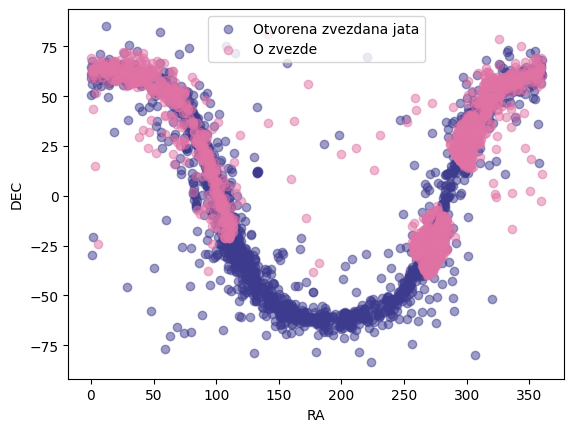

In [40]:
plt.figure()

plt.scatter(Angle(df_open_clean["RAJ2000"].astype(str), unit=u.hourangle).degree,
            Angle(df_open_clean["DEJ2000"].astype(str), unit=u.deg).degree, label='Otvorena zvezdana jata', alpha=0.5, color='#3D3B8E')

plt.scatter(o_data['ra'], o_data['dec'], label='O zvezde', color='#E072A4', alpha=0.5)

plt.legend()
plt.xlabel('RA')
plt.ylabel('DEC')

plt.show()

U prvom zadatku urađen je scatter podataka za O zvezde i otvorena zvezdana jata.

Kako su podaci za otvorena zvezdana jata dati u formatima h:m:s za rektascenziju i d:m:s za deklinaciju, iskorišćena je  funkcija .degree.

unit=u.hourangle za rektascenziju u časovnim uglovima i unit=u.deg za deklinaciju u stepenima, lučnim minutima i lučnim sekundama vraćaju decimalne stepene.

# 2. zadatak

In [41]:
def udaljenost(paralaksa):
    return 1/(paralaksa/1000)
    
o_data["distance_pc"] = udaljenost(o_data["parallax"])

print(o_data["distance_pc"])

o_data.to_csv("udaljenost_do_o_zvezda.csv", index=False)

0        1461.911048
1        2639.752590
2        6064.050551
3        2448.149775
4        2323.156261
            ...     
2995     2380.689761
2996     1545.327606
2997     4087.210471
2998    10283.552205
2999     9509.281296
Name: distance_pc, Length: 3000, dtype: float64


U drugom zadatku izračunata je udaljenost do O zvezda pomoću formule <span style="color: #E70E02;">$r = \frac{1}{\pi}$</span>.

<span style="color: #99DDC8;">parallax : Parallax (double, Angle[mas] )</span>

Paralaksa iz kataloga je podeljena sa 1000 da bi se iz mas prešlo u as

Rezultati se poklapaju sa podacima sa stranice https://en.wikipedia.org/wiki/List_of_O-type_stars

# 3. zadatak

In [42]:
def veliki_krug(ra, alphaw, i):
    ra = np.deg2rad(ra)
    alphaw = np.deg2rad(alphaw)
    i = np.deg2rad(i)

    dec=np.arctan(np.sin(ra-alphaw)*np.tan(i))

    return np.rad2deg(dec)

In [43]:
o_stars = pd.DataFrame({"RA": o_data["ra"],"DE": o_data["dec"]})
open_data = pd.DataFrame({"RA": Angle(df_open_clean["RAJ2000"].astype(str), unit=u.hourangle).degree,
                          'DE':Angle(df_open_clean["DEJ2000"].astype(str), unit=u.deg).degree})

data = pd.concat([o_stars,open_data], ignore_index=True)

ra = data["RA"].to_numpy(dtype=float)
dec = data["DE"].to_numpy(dtype=float)

In [44]:
def ls(alphaw,i):
    dec_model=veliki_krug(ra, alphaw, i)
    razlika=dec-dec_model
    S=np.sum(razlika**2)
    return S

In [45]:
result=minimize(
    lambda parameters: ls(parameters[0], parameters[1]),
    x0=[60,60], bounds=[(-180, 180), (0.1, 89.9)] #0.1 i 89.9 zbog definisanosti tangensa
)

alphaw_fit, i_fit = result.x

if alphaw_fit<0:
    alphaw_fit=alphaw_fit+360

alphaw_hms=Angle(alphaw_fit%360,unit=u.deg).to_string(unit=u.hourangle)

print("Najbolje alphaw:", alphaw_hms)
print("Najbolje i:", i_fit)
print("Minimalno S:", result.fun)

Najbolje alphaw: 18h58m08.82319491s
Najbolje i: 61.53986136243197
Minimalno S: 912395.9429602236


Dobijene vrednosti za i i alphaw su približno jednake usvojenim vrednostima za epohu J2000.

In [46]:
def alpha_png(alphaw):
    alphaw=alphaw/15
    return alphaw-6

def delta_png(i):
    return 90-i

alphapng=alpha_png(alphaw_fit)
deltapng=delta_png(i_fit)

print('Položaj galaktičkog pola- rektascenzija (h):',alphapng, ', deklinacija (deg):',deltapng)

Položaj galaktičkog pola- rektascenzija (h): 12.969117554142443 , deklinacija (deg): 28.46013863756803


Dobijene vrednosti su približno jednake vrednostima ekvatorskih koordinata severnog galaktičkog pola - ra: 12 51 26.28, dec: 27 07 42

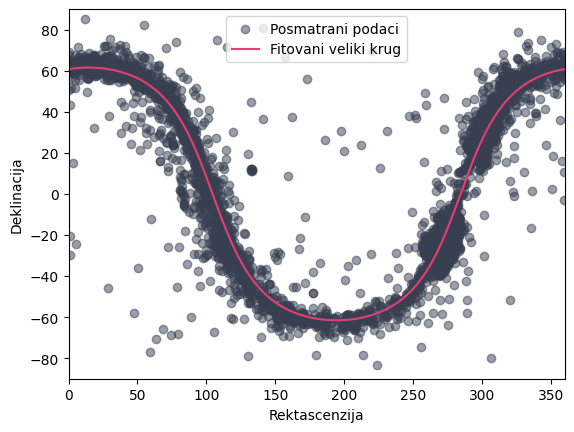

In [47]:
ra_model = np.linspace(0, 360, 1000)
dec_model = veliki_krug(ra_model, alphaw_fit, i_fit)

plt.figure()
plt.scatter(ra, dec, alpha=0.5, label="Posmatrani podaci", color='#373F51')
plt.plot(ra_model, dec_model, label="Fitovani veliki krug", color='#E43F6F')

plt.xlabel("Rektascenzija")
plt.ylabel("Deklinacija")
plt.xlim(0, 360)
plt.ylim(-90, 90)
plt.legend()
plt.show()

# 4. zadatak

In [48]:
coordinates=SkyCoord(df_globular_clean['RAJ2000'].astype(str),df_globular_clean['DEJ2000'].astype(str),
                    unit=(u.hourangle, u.deg),frame='icrs')

galactic=coordinates.galactic

df_globular_clean["l"] = galactic.l.deg
df_globular_clean["b"] = galactic.b.deg

print(df_globular_clean[["l", "b"]])

df_globular_clean.to_csv("globularna_jata_galakticke_koordinate.csv", index=False)

              l          b
0    305.895746 -44.889687
1    152.298408 -89.382849
2    301.532861 -46.247850
3    270.541630 -52.125765
4    130.067030  19.029031
..          ...        ...
142   53.377540 -35.777578
143   27.179945 -46.834884
144   30.512584 -47.680990
145   87.103384 -42.699804
146   53.386562 -63.477676

[147 rows x 2 columns]


U četvrtom zadatku su ekvatorske koordinate prevedene u galaktičke pomoću .galactic funkcije SkyCoord-a.

# 5. zadatak

In [49]:
bj=[]
bjc=[]
for j in range(1,12): #jer da počinje od nule bilo bi za j=0 arcsin(-1.2), što nije interval za arcsin
                      #12 jer za 10 oblasti imam 11 granica
    bj.append(np.asin(0.2*(j-6)))
for j in range(1,11):
    bjc.append(np.asin(0.2*(j-6)+0.1))

print(bj)
print()
print(np.degrees(bjc))

[np.float64(-1.5707963267948966), np.float64(-0.9272952180016123), np.float64(-0.6435011087932845), np.float64(-0.41151684606748806), np.float64(-0.2013579207903308), np.float64(0.0), np.float64(0.2013579207903308), np.float64(0.41151684606748806), np.float64(0.6435011087932845), np.float64(0.9272952180016123), np.float64(1.5707963267948966)]

[-64.15806724 -44.427004   -30.         -17.45760312  -5.73917048
   5.73917048  17.45760312  30.          44.427004    64.15806724]


In [50]:
df=pd.read_csv('globularna_jata_galakticke_koordinate.csv')
b=df['b'].to_numpy()

bj=np.degrees(bj)


n=[]
for i in range(10):
    n.append(np.sum(
        (b>bj[i]) & (b<bj[i+1])
    ))

print(n)
print()
print(np.sum(n), b.size)

[np.int64(2), np.int64(8), np.int64(8), np.int64(16), np.int64(40), np.int64(36), np.int64(16), np.int64(8), np.int64(7), np.int64(6)]

147 147


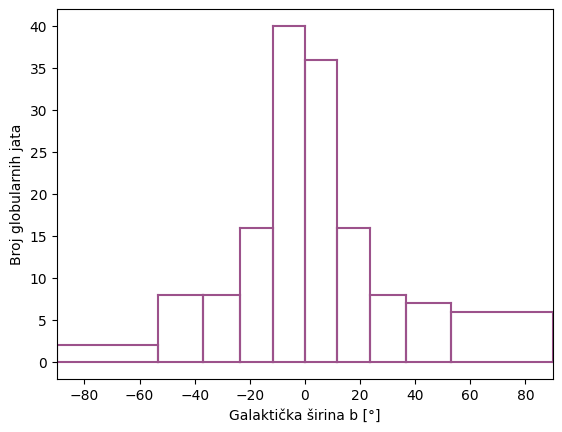

In [51]:
#napravila sam histogram pomoću pravougaonika jer nisam znala da podesim širine kako treba
plt.figure()

for i in range(10):
    leva=bj[i]
    desna=bj[i+1]
    visina=n[i]
    
    plt.plot([leva, desna], [0, 0], color='#9C528B')
    plt.plot([leva, leva], [0, visina], color='#9C528B')
    plt.plot([leva, desna], [visina, visina], color='#9C528B')
    plt.plot([desna, desna], [0, visina], color='#9C528B')

plt.xlabel('Galaktička širina b [°]')
plt.ylabel('Broj globularnih jata')
plt.xlim(-90, 90)
plt.show()

In [52]:
bjc=np.degrees(bjc)

bmax=(np.sum(n*bjc))/(np.sum(n))
print('bmax=', bmax)

bmax= 1.2874053267854328


### Podela od 20 zona

[np.float64(-1.5707963267948966), np.float64(-1.1197695149986342), np.float64(-0.9272952180016123), np.float64(-0.7753974966107532), np.float64(-0.6435011087932845), np.float64(-0.5235987755982989), np.float64(-0.41151684606748806), np.float64(-0.3046926540153976), np.float64(-0.2013579207903308), np.float64(-0.1001674211615598), np.float64(0.0), np.float64(0.1001674211615598), np.float64(0.2013579207903308), np.float64(0.3046926540153976), np.float64(0.41151684606748806), np.float64(0.5235987755982989), np.float64(0.6435011087932845), np.float64(0.7753974966107532), np.float64(0.9272952180016123), np.float64(1.1197695149986342), np.float64(1.5707963267948966)]

[-71.80512766 -58.21166938 -48.59037789 -40.54160187 -33.36701297
 -26.74368395 -20.48731511 -14.47751219  -8.62692656  -2.86598398
   2.86598398   8.62692656  14.47751219  20.48731511  26.74368395
  33.36701297  40.54160187  48.59037789  58.21166938  71.80512766]

[np.int64(1), np.int64(1), np.int64(6), np.int64(2), np.int64(3

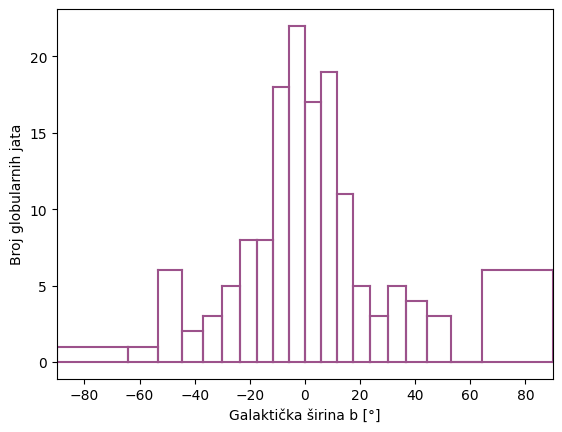

bmax20= 1.5349679924830142


In [53]:
#prekopiran gornji kod, ali zamenjeni brojevi stubića
#h=0.1 i polovina visine je 0.05
#srednji indeks je j=11 (za koji je sinb=0)

bj=[]
bjc=[]
for j in range(1,22):
    bj.append(np.asin(0.1*(j-11)))
for j in range(1,21):
    bjc.append(np.asin(0.1*(j-11)+0.05))

print(bj)
print()
print(np.degrees(bjc))
print()

df=pd.read_csv('globularna_jata_galakticke_koordinate.csv')
b=df['b'].to_numpy()

bj=np.degrees(bj)


n=[]
for i in range(20):
    n.append(np.sum(
        (b>bj[i]) & (b<bj[i+1])
    ))

print(n)
print()
print(np.sum(n), b.size)

plt.figure()

for i in range(20):
    leva=bj[i]
    desna=bj[i+1]
    visina=n[i]
    
    plt.plot([leva, desna], [0, 0], color='#9C528B')
    plt.plot([leva, leva], [0, visina], color='#9C528B')
    plt.plot([leva, desna], [visina, visina], color='#9C528B')
    plt.plot([desna, desna], [0, visina], color='#9C528B')

plt.xlabel('Galaktička širina b [°]')
plt.ylabel('Broj globularnih jata')
plt.xlim(-90, 90)
plt.show()

bjc=np.degrees(bjc)

bmax20=(np.sum(n*bjc))/(np.sum(n))
print('bmax20=', bmax20)

Očekivali bismo da je $b_{\max} = 0^\circ$ , budući da je to latituda koja odgovara disku Galaksije, no vidimo da postoje odstupanja: $b_{\max10} = 1.29^\circ$ i $b_{\max20} = 1.53^\circ$

# 6. zadatak

[-180, -144, -108, -72, -36, 0, 36, 72, 108, 144, 180]

ljc: [-162, -126, -90, -54, -18, 18, 54, 90, 126, 162]

[np.int64(2), np.int64(5), np.int64(6), np.int64(12), np.int64(45), np.int64(58), np.int64(14), np.int64(2), np.int64(1), np.int64(2)]

147 147



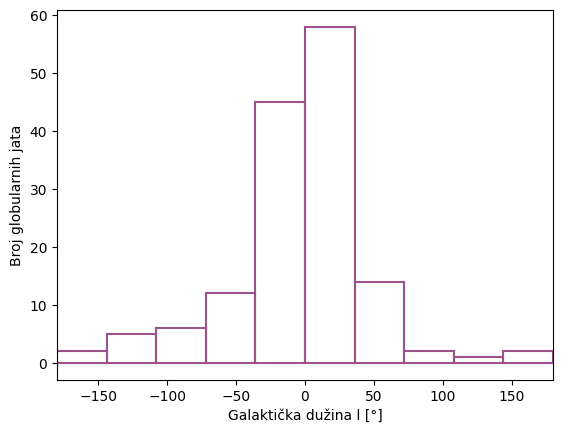

lmax= -3.5510204081632653


In [54]:
lj=[]
ljc=[]
for j in range(0,11):
    lj.append(-180+j*36) #360/10=36
for j in range(0,10):
    ljc.append(-180+j*36+18) #36/2=18

print(lj)
print()
print('ljc:',ljc)
print()


df=pd.read_csv('globularna_jata_galakticke_koordinate.csv')
l=df['l'].to_numpy()

l=(l+180)%360-180 #jer je u katalogu od 0 do 360, a interval -180, 180 mi treba za računanje lmax

n=[]
for i in range(10):
    n.append(np.sum(
        (l>=lj[i]) & (l<lj[i+1])
    ))

print(n)
print()
print(np.sum(n), l.size)
print()


plt.figure()

for i in range(10):
    leva=lj[i]
    desna=lj[i+1]
    visina=n[i]
    
    plt.plot([leva, desna], [0, 0], color='#9C528B')
    plt.plot([leva, leva], [0, visina], color='#9C528B')
    plt.plot([leva, desna], [visina, visina], color='#9C528B')
    plt.plot([desna, desna], [0, visina], color='#9C528B')

plt.xlabel('Galaktička dužina l [°]')
plt.ylabel('Broj globularnih jata')
plt.xlim(-180, 180)
plt.show()

lmax=(np.sum(np.array(n)*np.array(ljc)))/(np.sum(n))
print('lmax=', lmax)

### 20 stubova

[-180, -162, -144, -126, -108, -90, -72, -54, -36, -18, 0, 18, 36, 54, 72, 90, 108, 126, 144, 162, 180]

ljc: [-171, -153, -135, -117, -99, -81, -63, -45, -27, -9, 9, 27, 45, 63, 81, 99, 117, 135, 153, 171]

[np.int64(1), np.int64(1), np.int64(2), np.int64(3), np.int64(3), np.int64(3), np.int64(7), np.int64(5), np.int64(13), np.int64(32), np.int64(43), np.int64(15), np.int64(8), np.int64(6), np.int64(2), np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(1)]

147 147



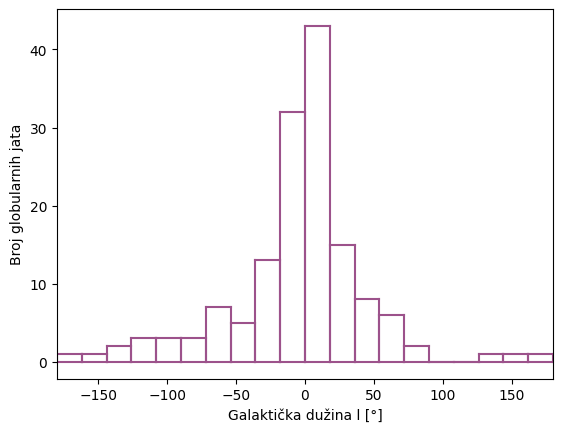

lmax20= -4.346938775510204


In [55]:
lj=[]
ljc=[]
for j in range(0,21):
    lj.append(-180+j*18) #360/20=18
for j in range(0,20):
    ljc.append(-180+j*18+9) #18/2=9

print(lj)
print()
print('ljc:',ljc)
print()


df=pd.read_csv('globularna_jata_galakticke_koordinate.csv')
l=df['l'].to_numpy()

l=(l+180)%360-180

n=[]
for i in range(20):
    n.append(np.sum(
        (l>=lj[i]) & (l<lj[i+1])
    ))

print(n)
print()
print(np.sum(n), l.size)
print()


plt.figure()

for i in range(20):
    leva=lj[i]
    desna=lj[i+1]
    visina=n[i]
    
    plt.plot([leva, desna], [0, 0], color='#9C528B')
    plt.plot([leva, leva], [0, visina], color='#9C528B')
    plt.plot([leva, desna], [visina, visina], color='#9C528B')
    plt.plot([desna, desna], [0, visina], color='#9C528B')

plt.xlabel('Galaktička dužina l [°]')
plt.ylabel('Broj globularnih jata')
plt.xlim(-180, 180)
plt.show()


lmax20=(np.sum(np.array(n)*np.array(ljc)))/(np.sum(n))
print('lmax20=', lmax20)

Ovde nisam mogla da koristim arcsin zbog njegove oblasti definisanosti, no su zone jednake širine po uglu.

Ostatak zadatka je sličan prethodnom.

# 7. zadatak

Očekivane vrednosti su $b_{\max} = 0^\circ$ i $l_{\max} = 0^\circ$

Ukoliko Galaksiju podelimo na 10 oblasti, dobijamo $b_{\max10} = 1.29^\circ$ i $l_{\max10} = -3.55^\circ$ , a ukoliko je podelimo na 20, dobijamo $b20_{\max} = 1.53^\circ$ i $l_{\max20} = -4.35^\circ$ , što je približno jednako očekivanoj vrednosti. Odstupanje može biti posledica veličine uzorka i načina određivanja maksimuma.

In [56]:
centar=SkyCoord(l=0*u.deg, b=0*u.deg, frame='galactic')

ekv=centar.transform_to(FK5(equinox='J2000'))

racG=ekv.ra.to(u.hourangle)
deccG=ekv.dec.to(u.deg)

print("RA =", racG)
print("DEC =", deccG)

RA = 17h45m37.19909617s
DEC = -28d56m10.22065221s


Sagittarius_A*: https://en.wikipedia.org/wiki/Sagittarius_A*

Epoch J2000  
Right ascension	17h 45m 40.0409s  
Declination	−29$\circ$ 0′ 28.118″

Izračunate koordinate centra Galaksije su probližno jednake stvarnim koordinatama centra Galaksije (supermasivne crne rupe Sagittarius A*
).